# Comparação de modelos de churn

Nesta etapa, comparamos Regressão Logística, Random Forest e MLP usando validação cruzada aninhada. A validação interna ajusta os hiperparâmetros; os folds externos estimam o desempenho sem participar desse ajuste. O conjunto de dados já foi usado em experiências anteriores, inclusive numa avaliação de teste repetida. Por isso, esses resultados de teste serão tratados apenas como históricos e exploratórios; não há uma amostra independente disponível para uma avaliação final imparcial.

## 1. Preparar os dados e o pré-processamento

Carregamos os mesmos dados e aplicamos a limpeza documentada na EDA. O pré-processamento fica dentro de cada pipeline e é ajustado somente nos dados de treino de cada fold. Como todos os registros já participaram de experiências anteriores, não separaremos um novo conjunto de teste nem apresentaremos os números históricos como avaliação final.

In [1]:
RANDOM_STATE = 42
OUTER_FOLDS = 5
INNER_FOLDS = 3

import json
import platform
import time
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

np.random.seed(RANDOM_STATE)
df = pd.read_csv("../data/telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
y = df["Churn"].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("A coluna Churn contém valores fora das categorias No/Yes.")
X = df.drop(columns=["customerID", "Churn"])

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, make_column_selector(dtype_include="number")),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            make_column_selector(dtype_exclude="number"),
        ),
    ]
)
outer_cv = StratifiedKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "auc": "roc_auc",
}
model_specs = {
    "Regressão Logística": {
        "estimator": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "parameters": {"classifier__C": [0.1, 1.0, 10.0]},
        "n_iter": 3,
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        "parameters": {
            "classifier__n_estimators": [150, 250],
            "classifier__max_depth": [None, 12],
            "classifier__min_samples_leaf": [1, 3],
        },
        "n_iter": 4,
    },
    "MLP": {
        "estimator": MLPClassifier(
            hidden_layer_sizes=(64, 32),
            early_stopping=True,
            max_iter=500,
            random_state=RANDOM_STATE,
        ),
        "parameters": {
            "classifier__alpha": [0.0001, 0.001, 0.01],
            "classifier__learning_rate_init": [0.001, 0.005],
        },
        "n_iter": 4,
    },
}
print(f"Registros: {len(X)}; atributos preditores: {X.shape[1]}")
print(f"Classe churn: {y.mean():.2%}; nulos em TotalCharges: {X['TotalCharges'].isna().sum()}")
print(f"Validação externa: {OUTER_FOLDS} folds; busca interna: {INNER_FOLDS} folds.")

Registros: 7043; atributos preditores: 19
Classe churn: 26.54%; nulos em TotalCharges: 11
Validação externa: 5 folds; busca interna: 3 folds.


## 2. Comparação com validação cruzada aninhada

Em cada fold externo, a busca de hiperparâmetros usa apenas os folds internos do subconjunto de treino. A configuração selecionada é então avaliada no fold externo, que não participou do ajuste. Repetimos isso para as três famílias de modelos e também medimos a Regressão Logística com `C=1` como baseline fixo. Assim, os resultados externos evitam o otimismo de avaliar os hiperparâmetros nos mesmos folds usados para escolhê-los.

In [2]:
def build_pipeline(estimator):
    """Create a preprocessing and classification pipeline."""
    return Pipeline(
        steps=[("preprocessor", clone(preprocessor)), ("classifier", estimator)]
    )


def calculate_metrics(y_true, predictions, probabilities):
    """Calculate classification metrics for the positive churn class."""
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "auc": roc_auc_score(y_true, probabilities),
    }


nested_scores = {"Baseline — Regressão Logística (C=1)": []}
nested_scores.update({name: [] for name in model_specs})
outer_predictions = {"Baseline — Regressão Logística (C=1)": np.full(len(y), np.nan)}
outer_probabilities = {"Baseline — Regressão Logística (C=1)": np.full(len(y), np.nan)}
search_scores = {name: [] for name in model_specs}
search_params = {name: [] for name in model_specs}
outer_predictions.update({name: np.full(len(y), np.nan) for name in model_specs})
outer_probabilities.update({name: np.full(len(y), np.nan) for name in model_specs})
fit_times = {"Baseline — Regressão Logística (C=1)": 0.0, **{name: 0.0 for name in model_specs}}

for fold_number, (train_indices, validation_indices) in enumerate(outer_cv.split(X, y), start=1):
    X_outer_train = X.iloc[train_indices]
    X_outer_validation = X.iloc[validation_indices]
    y_outer_train = y.iloc[train_indices]
    y_outer_validation = y.iloc[validation_indices]
    inner_cv = StratifiedKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE + fold_number,
    )

    baseline_name = "Baseline — Regressão Logística (C=1)"
    baseline_pipeline = build_pipeline(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    )
    baseline_start = time.perf_counter()
    baseline_pipeline.fit(X_outer_train, y_outer_train)
    fit_times[baseline_name] += time.perf_counter() - baseline_start
    baseline_prediction = baseline_pipeline.predict(X_outer_validation)
    baseline_probability = baseline_pipeline.predict_proba(X_outer_validation)[:, 1]
    nested_scores[baseline_name].append(
        calculate_metrics(y_outer_validation, baseline_prediction, baseline_probability)
    )
    outer_predictions[baseline_name][validation_indices] = baseline_prediction
    outer_probabilities[baseline_name][validation_indices] = baseline_probability

    for model_name, spec in model_specs.items():
        search = RandomizedSearchCV(
            estimator=build_pipeline(clone(spec["estimator"])),
            param_distributions=spec["parameters"],
            n_iter=spec["n_iter"],
            scoring="f1",
            refit=True,
            cv=inner_cv,
            random_state=RANDOM_STATE,
            n_jobs=1,
            error_score="raise",
            return_train_score=False,
        )
        search_start = time.perf_counter()
        search.fit(X_outer_train, y_outer_train)
        fit_times[model_name] += time.perf_counter() - search_start
        prediction = search.predict(X_outer_validation)
        probability = search.predict_proba(X_outer_validation)[:, 1]
        nested_scores[model_name].append(
            calculate_metrics(y_outer_validation, prediction, probability)
        )
        search_scores[model_name].append(float(search.best_score_))
        search_params[model_name].append(search.best_params_)
        outer_predictions[model_name][validation_indices] = prediction
        outer_probabilities[model_name][validation_indices] = probability
    print(f"Fold externo {fold_number}/{OUTER_FOLDS} concluído.")

comparison_rows = []
for model_name, fold_metrics in nested_scores.items():
    row = {"modelo": model_name, "tempo_treino_s": fit_times[model_name]}
    for metric in scoring:
        values = np.array([fold[metric] for fold in fold_metrics])
        row[f"{metric}_media"] = float(values.mean())
        row[f"{metric}_dp"] = float(values.std(ddof=1))
    if model_name in search_scores:
        row["parametros_por_fold"] = search_params[model_name]
        row["f1_cv_interna_media"] = float(np.mean(search_scores[model_name]))
    else:
        row["parametros_por_fold"] = [{"classifier__C": 1.0} for _ in range(OUTER_FOLDS)]
        row["f1_cv_interna_media"] = np.nan
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    ["f1_media", "auc_media"], ascending=[False, False]
).reset_index(drop=True)
summary_table = pd.DataFrame({"modelo": comparison_df["modelo"]})
for metric, label in [
    ("accuracy", "Acurácia"),
    ("precision", "Precisão"),
    ("recall", "Recall"),
    ("f1", "F1"),
    ("auc", "AUC-ROC"),
]:
    summary_table[f"{label} (média ± dp)"] = comparison_df.apply(
        lambda row, key=metric: f"{row[f'{key}_media']:.4f} ± {row[f'{key}_dp']:.4f}",
        axis=1,
    )
summary_table["tempo total (s)"] = comparison_df["tempo_treino_s"].map(lambda value: f"{value:.2f}")
display(summary_table)

champion_name = comparison_df.loc[0, "modelo"]
if champion_name.startswith("Baseline"):
    champion_family = "Regressão Logística"
    final_parameters = {"classifier__C": 1.0}
else:
    champion_family = champion_name
print(f"Modelo com maior F1 externo: {champion_name}")
print("Hiperparâmetros externos foram ajustados apenas nos respectivos folds internos.")
print("A escolha entre famílias ainda pode gerar viés de seleção; consultar nova amostra independente antes de alegar desempenho prospectivo.")

Fold externo 1/5 concluído.
Fold externo 2/5 concluído.
Fold externo 3/5 concluído.
Fold externo 4/5 concluído.
Fold externo 5/5 concluído.
Modelo com maior F1 externo: Regressão Logística
Hiperparâmetros externos foram ajustados apenas nos respectivos folds internos.
A escolha entre famílias ainda pode gerar viés de seleção; consultar nova amostra independente antes de alegar desempenho prospectivo.


,modelo,Acurácia (média ± dp),Precisão (média ± dp),Recall (média ± dp),F1 (média ± dp),AUC-ROC (média ± dp),tempo total (s)
0,Regressão Logística,0.8058 ± 0.0117,0.6589 ± 0.0235,0.5548 ± 0.0336,0.6023 ± 0.0290,0.8450 ± 0.0149,2.73
1,Baseline — Regressão Logística (C=1),0.8052 ± 0.0125,0.6577 ± 0.0249,0.5532 ± 0.0355,0.6008 ± 0.0308,0.8450 ± 0.0149,0.26
2,Random Forest,0.8021 ± 0.0119,0.6628 ± 0.0278,0.5168 ± 0.0283,0.5807 ± 0.0279,0.8399 ± 0.0147,57.51
3,MLP,0.7997 ± 0.0086,0.6689 ± 0.0220,0.4853 ± 0.0215,0.5624 ± 0.0209,0.8407 ± 0.0145,19.07


## 3. Curvas ROC e inspeção do baseline

As curvas ROC usam previsões out-of-fold: cada registro é previsto por um pipeline que não foi ajustado naquele fold externo. A matriz de confusão abaixo é agregada das previsões externas do baseline fixo. Não existe avaliação de teste independente nesta etapa.

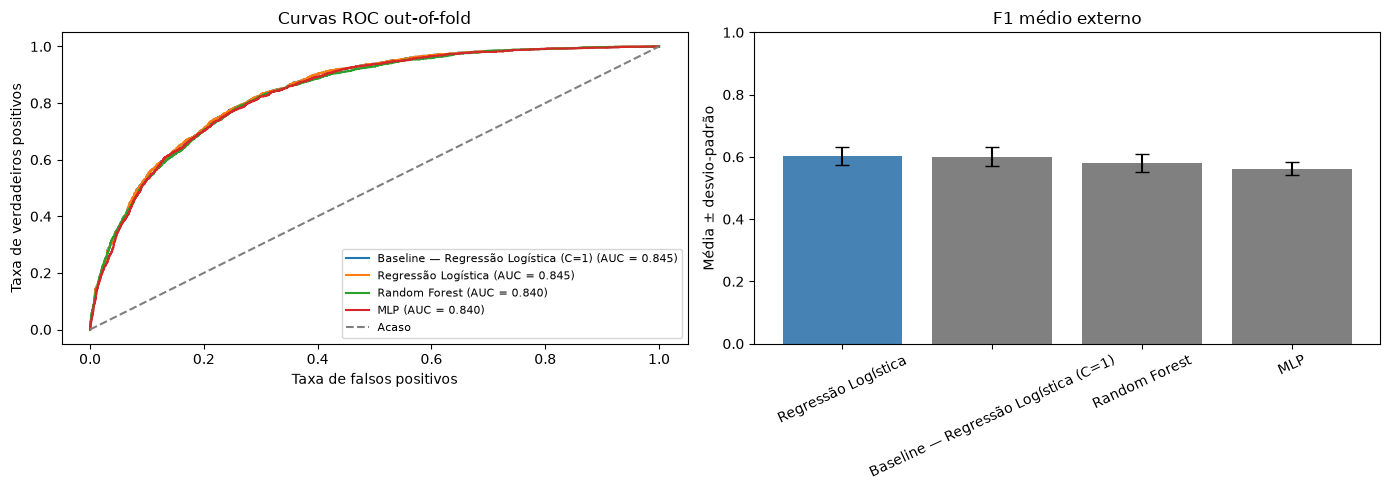

,Previsto: não churn,Previsto: churn
Real: não churn,4637,537
Real: churn,835,1034


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for model_name in nested_scores:
    probabilities = outer_probabilities[model_name]
    fpr, tpr, _ = roc_curve(y, probabilities)
    axes[0].plot(fpr, tpr, label=f"{model_name} (AUC = {auc(fpr, tpr):.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Acaso")
axes[0].set_title("Curvas ROC out-of-fold")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos")
axes[0].legend(loc="lower right", fontsize=8)

for ax, metric, title in zip(
    axes[1:], ["f1", "auc"], ["F1 médio externo", "AUC-ROC média externa"]
):
    errors = comparison_df[f"{metric}_dp"]
    ax.bar(
        comparison_df["modelo"],
        comparison_df[f"{metric}_media"],
        yerr=errors,
        capsize=5,
        color=["steelblue" if name == champion_name else "gray" for name in comparison_df["modelo"]],
    )
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylabel("Média ± desvio-padrão")
fig.tight_layout()
plt.show()

baseline_name = "Baseline — Regressão Logística (C=1)"
baseline_oof_matrix = confusion_matrix(
    y, outer_predictions[baseline_name].astype(int), labels=[0, 1]
)
display(
    pd.DataFrame(
        baseline_oof_matrix,
        index=["Real: não churn", "Real: churn"],
        columns=["Previsto: não churn", "Previsto: churn"],
    )
)

## 4. Ajustar e salvar o pipeline selecionado

Depois da comparação aninhada, ajustamos a busca da família selecionada em todos os dados disponíveis para gerar o artefato destinado à Etapa 3. Os escores aninhados são estimativas de validação, não métricas de teste. Como os dados atuais já foram explorados, uma avaliação final imparcial exigirá novos dados rotulados que não participem do treinamento.

In [4]:
final_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
if champion_name.startswith("Baseline"):
    final_estimator = build_pipeline(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    )
    final_estimator.fit(X, y)
    final_model = final_estimator
    final_parameters = {"classifier__C": 1.0}
else:
    champion_spec = model_specs[champion_family]
    final_search = RandomizedSearchCV(
        estimator=build_pipeline(clone(champion_spec["estimator"])),
        param_distributions=champion_spec["parameters"],
        n_iter=champion_spec["n_iter"],
        scoring="f1",
        refit=True,
        cv=final_cv,
        random_state=RANDOM_STATE,
        n_jobs=1,
        error_score="raise",
        return_train_score=False,
    )
    final_search.fit(X, y)
    final_model = final_search.best_estimator_
    final_parameters = final_search.best_params_

model_path = Path("../models/churn_model.joblib")
metadata_path = Path("../models/model_metadata.json")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, model_path)
model_size_bytes = model_path.stat().st_size
if model_size_bytes > 50 * 1024 * 1024:
    raise ValueError(f"O modelo excede 50 MB: {model_size_bytes} bytes.")

champion_cv_row = comparison_df.loc[comparison_df["modelo"] == champion_name].iloc[0]
baseline_cv_f1 = float(comparison_df.loc[comparison_df["modelo"] == "Baseline — Regressão Logística (C=1)", "f1_media"].iloc[0])
nested_f1_delta_vs_baseline = float(champion_cv_row["f1_media"] - baseline_cv_f1)
metadata = {
    "model_name": champion_name,
    "best_parameters": final_parameters,
    "random_state": RANDOM_STATE,
    "threshold": 0.5,
    "positive_class": "Churn = Yes",
    "features": X.columns.tolist(),
    "training_date": date.today().isoformat(),
    "train_size": int(len(X)),
    "test_size": None,
    "evaluation_status": "nested_cross_validation; independent_test_set_unavailable",
    "previous_test_metrics_status": "exploratory_only; prior results were inspected and the comparison test was executed twice",
    "cross_validation": {
        "strategy": "nested StratifiedKFold",
        "outer_folds": OUTER_FOLDS,
        "inner_folds": INNER_FOLDS,
        "shuffle": True,
        "selection_metric": "f1",
        "metrics_mean": {
            metric: float(champion_cv_row[f"{metric}_media"])
            for metric in ["accuracy", "precision", "recall", "f1", "auc"]
        },
        "metrics_std": {
            metric: float(champion_cv_row[f"{metric}_dp"])
            for metric in ["accuracy", "precision", "recall", "f1", "auc"]
        },
    },
    "test_metrics": None,
    "baseline_nested_cv_f1": baseline_cv_f1,
    "nested_cv_f1_delta_vs_baseline": nested_f1_delta_vs_baseline,
    "model_size_bytes": int(model_size_bytes),
    "versions": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}
metadata_path.write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

experiment_columns = [
    "experimento", "modelo", "parametros", "f1_cv_media", "f1_cv_dp",
    "auc_cv_media", "auc_cv_dp", "precisao_cv", "recall_cv",
    "tempo_treino_s", "f1_teste", "auc_teste", "data",
]
experiments_path = Path("../docs/experimentos.csv")
experiments_df = pd.read_csv(experiments_path)
if experiments_df.columns.tolist() != experiment_columns:
    raise ValueError("O cabeçalho de docs/experimentos.csv mudou inesperadamente.")

historic_rows = experiments_df["experimento"].isin(
    ["baseline_logistic_regression", "logistic_regression_tuned"]
)
experiments_df.loc[historic_rows, "experimento"] = experiments_df.loc[historic_rows, "experimento"] + "_exploratory_test"
experiments_df.loc[historic_rows, "parametros"] = experiments_df.loc[historic_rows, "parametros"].astype(str).map(
    lambda value: json.dumps({"previous_test_status": "exploratory_only", "original_parameters": value}, sort_keys=True)
)

slug_by_model = {
    "Baseline — Regressão Logística (C=1)": "baseline_logistic_regression_nested_cv",
    "Regressão Logística": "logistic_regression_nested_cv",
    "Random Forest": "random_forest_nested_cv",
    "MLP": "mlp_nested_cv",
}
new_rows = []
for _, row in comparison_df.iterrows():
    parameters = row["parametros_por_fold"]
    new_rows.append(
        {
            "experimento": slug_by_model[row["modelo"]],
            "modelo": row["modelo"],
            "parametros": json.dumps(parameters, sort_keys=True),
            "f1_cv_media": row["f1_media"],
            "f1_cv_dp": row["f1_dp"],
            "auc_cv_media": row["auc_media"],
            "auc_cv_dp": row["auc_dp"],
            "precisao_cv": row["precision_media"],
            "recall_cv": row["recall_media"],
            "tempo_treino_s": row["tempo_treino_s"],
            "f1_teste": np.nan,
            "auc_teste": np.nan,
            "data": date.today().isoformat(),
        }
    )
new_rows_df = pd.DataFrame(new_rows, columns=experiment_columns)
experiments_df = experiments_df.loc[
    ~experiments_df["experimento"].isin(new_rows_df["experimento"])
]
experiments_df = pd.concat([experiments_df, new_rows_df], ignore_index=True)
experiments_df.to_csv(experiments_path, index=False)

report_headers = ["Modelo", "Acurácia", "Precisão", "Recall", "F1", "AUC-ROC", "Tempo total (s)"]
report_lines = ["| " + " | ".join(report_headers) + " |", "| " + " | ".join(["---"] * len(report_headers)) + " |"]
for _, row in comparison_df.iterrows():
    report_lines.append(
        "| " + " | ".join(
            [
                str(row["modelo"]),
                f"{row['accuracy_media']:.4f} ± {row['accuracy_dp']:.4f}",
                f"{row['precision_media']:.4f} ± {row['precision_dp']:.4f}",
                f"{row['recall_media']:.4f} ± {row['recall_dp']:.4f}",
                f"{row['f1_media']:.4f} ± {row['f1_dp']:.4f}",
                f"{row['auc_media']:.4f} ± {row['auc_dp']:.4f}",
                f"{row['tempo_treino_s']:.2f}",
            ]
        ) + " |"
    )
report = "\n".join(
    [
        "# Comparação de modelos de churn",
        "",
        "## Integridade da avaliação",
        "",
        "Na execução inicial, a avaliação do teste foi repetida após uma correção de código, e os resultados também ficaram visíveis. Embora não tenham orientado a escolha dos modelos, esse conjunto não pode mais ser considerado um teste cego independente. Como todos os registros do CSV participaram de análises anteriores, não existe neste dataset uma amostra de teste intocada. As métricas históricas de teste foram mantidas no CSV e nos notebooks, mas estão identificadas como exploratórias e não são usadas para escolher o campeão nem declaradas como resultado final.",
        "",
        "A prática adotada nesta revisão é validação cruzada aninhada: cinco folds externos estimam o desempenho e três folds internos ajustam hiperparâmetros. Cada transformação é ajustada somente no treino do fold interno. Os resultados abaixo são estimativas de validação; escolher entre famílias de modelos pode ainda produzir otimismo de seleção. Uma avaliação prospectiva requer novos dados rotulados, coletados após o congelamento do pipeline.",
        "",
        "## Protocolo e resultados da validação externa",
        "",
        "O baseline fixo usa Regressão Logística com `C=1`; as demais entradas ajustam os hiperparâmetros nos folds internos. Valores apresentados como média ± desvio-padrão entre os folds externos.",
        "",
        *report_lines,
        "",
        "## Campeão e artefato",
        "",
        f"Pelo maior F1 médio externo, o modelo selecionado é **{champion_name}**. O pipeline salvo foi reajustado em todos os registros disponíveis, com parâmetros finais `{json.dumps(final_parameters, ensure_ascii=False, sort_keys=True)}`. Não há métricas de teste finais (`test_metrics: null`), pois seria incorreto apresentar como independente um conjunto já consultado.",
        f"A diferença observada para o baseline fixo (C=1) na validação externa é {nested_f1_delta_vs_baseline:+.4f} em F1. Ela é pequena frente à variação entre folds; portanto, não afirmamos que o ganho seja estatisticamente confiável nem que o modelo supere o baseline de forma generalizável.",
        "",
        f"O pipeline completo, incluindo pré-processamento, está em `models/churn_model.joblib` ({model_size_bytes:,} bytes). Os metadados em `models/model_metadata.json` registram o método aninhado, as versões e o estado da avaliação.",
        "",
        "## Próxima avaliação",
        "",
        "Antes de afirmar desempenho em produção, congele este pipeline e avalie-o uma única vez em novos dados rotulados que não tenham sido usados em exploração, ajuste ou seleção. Não escolha limiar nem hiperparâmetros com base nessa avaliação prospectiva.",
        "",
    ]
)
Path("../docs/comparacao-modelos.md").write_text(report, encoding="utf-8")
print(f"Campeão: {champion_name}")
print(f"Pipeline: {model_size_bytes:,} bytes")
print("Relatório e CSV atualizados com métricas aninhadas; sem alegação de teste independente.")
display(experiments_df.tail(len(new_rows_df)))

Campeão: Regressão Logística
Pipeline: 8,058 bytes
Relatório e CSV atualizados com métricas aninhadas; sem alegação de teste independente.


,experimento,modelo,parametros,f1_cv_media,f1_cv_dp,auc_cv_media,auc_cv_dp,precisao_cv,recall_cv,tempo_treino_s,f1_teste,auc_teste,data
4,logistic_regression_nested_cv,Regressão Logística,"[{""classifier__C"": 1.0}, {""classifier__C"": 1.0}, {""classifier__C"": 1.0}, {""classifier__C"": 10.0}, {""classifier__C"": 10.0}]",0.602255,0.029039,0.845002,0.014907,0.658869,0.554816,2.729988,NaN,NaN,2026-10-26
5,baseline_logistic_regression_nested_cv,Baseline — Regressão Logística (C=1),"[{""classifier__C"": 1.0}, {""classifier__C"": 1.0}, {""classifier__C"": 1.0}, {""classifier__C"": 1.0}, {""classifier__C"": 1.0}]",0.600828,0.030831,0.844974,0.014929,0.657734,0.553211,0.255853,NaN,NaN,2026-10-26
6,random_forest_nested_cv,Random Forest,"[{""classifier__max_depth"": 12, ""classifier__min_samples_leaf"": 3, ""classifier__n_estimators"": 250}, {""classifier__max_depth"": 12, ""classifier__min_samples_leaf"": 3, ""classifier__n_estimators"": 250}, {""classifier__max_depth"": 12, ""classifier__min_samples_leaf"": 1, ""classifier__n_estimators"": 250}, {""classifier__max_depth"": 12, ""classifier__min_samples_leaf"": 1, ""classifier__n_estimators"": 250}, {""classifier__max_depth"": 12, ""classifier__min_samples_leaf"": 3, ""classifier__n_estimators"": 250}]",0.580718,0.027934,0.839853,0.014733,0.662792,0.516830,57.511157,NaN,NaN,2026-10-26
7,mlp_nested_cv,MLP,"[{""classifier__alpha"": 0.01, ""classifier__learning_rate_init"": 0.005}, {""classifier__alpha"": 0.0001, ""classifier__learning_rate_init"": 0.001}, {""classifier__alpha"": 0.01, ""classifier__learning_rate_init"": 0.005}, {""classifier__alpha"": 0.001, ""classifier__learning_rate_init"": 0.001}, {""classifier__alpha"": 0.0001, ""classifier__learning_rate_init"": 0.005}]",0.562371,0.020873,0.840679,0.014491,0.668866,0.485275,19.071179,NaN,NaN,2026-10-26


## 5. Conclusões e próximos passos

A validação aninhada reduz o viés de ajuste de hiperparâmetros, mas a escolha entre famílias ainda pode ser otimista. A diferença de F1 externo em relação ao baseline fixo é pequena frente à variação entre folds; não há evidência suficiente para afirmar uma melhora confiável. O conjunto de teste antigo permanece apenas exploratório e não será reutilizado. Para uma estimativa final de desempenho, é necessário obter dados rotulados novos, congelar o pipeline e avaliá-lo uma única vez. Até lá, o modelo salvo é um artefato de desenvolvimento, não uma garantia de desempenho em produção.